In [1]:
import os
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Auto-detect dataset directory (local workspace or Kaggle)
data_dir = "Dataset" if os.path.exists("Dataset") else "/kaggle/input"
print(f"Data directory: {data_dir}")

if os.path.exists(data_dir):
    for dirname, subdirs, filenames in os.walk(data_dir):
        txt_files = [f for f in filenames if f.endswith('.txt')]
        if txt_files:
            print(f"  {dirname}: {len(txt_files)} text documents found")
else:
    print("Data directory not found. Please ensure 'Dataset' folder is present.")

Data directory: Dataset
  Dataset\bbc\business: 510 text documents found
  Dataset\bbc\entertainment: 386 text documents found
  Dataset\bbc\politics: 417 text documents found
  Dataset\bbc\sport: 511 text documents found
  Dataset\bbc\tech: 401 text documents found
  Dataset\bbc-fulltext (document classification)\bbc\business: 510 text documents found
  Dataset\bbc-fulltext (document classification)\bbc\entertainment: 386 text documents found
  Dataset\bbc-fulltext (document classification)\bbc\politics: 417 text documents found
  Dataset\bbc-fulltext (document classification)\bbc\sport: 511 text documents found
  Dataset\bbc-fulltext (document classification)\bbc\tech: 401 text documents found


# Importing Libraries

In [2]:
import os
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split

import nltk
from nltk import word_tokenize
from nltk.stem import WordNetLemmatizer, PorterStemmer
from nltk.corpus import wordnet
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [3]:
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("averaged_perceptron_tagger")
nltk.download("averaged_perceptron_tagger_eng")

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

# Loading Data

In [4]:
# Auto-detect BBC dataset path across environments (Local Windows, Kaggle, Colab)
candidate_paths = [
    "Dataset/bbc",
    "Dataset/bbc-fulltext (document classification)/bbc",
    "/kaggle/input/datasets/shivamkushwaha/bbc-full-text-document-classification/bbc",
    "../input/bbc-fulltext-and-category/bbc-fulltext (document classification)/bbc"
]

base_path = None
for p in candidate_paths:
    if os.path.exists(p):
        base_path = p
        break

if base_path is None:
    raise FileNotFoundError("Could not locate the BBC dataset directory. Checked: " + str(candidate_paths))

print(f"Loading dataset from: {base_path}")

# Standardize category labels to user-requested major folders:
# politics, sports, tech, entertainment, business
CATEGORY_MAP = {
    'business': 'business',
    'entertainment': 'entertainment',
    'politics': 'politics',
    'sport': 'sports',
    'sports': 'sports',
    'tech': 'tech'
}

texts = []
labels = []
titles = []

for category in os.listdir(base_path):
    category_path = os.path.join(base_path, category)
    
    if os.path.isdir(category_path):
        mapped_category = CATEGORY_MAP.get(category, category)
        for file in os.listdir(category_path):
            if file.endswith('.txt') and file.lower() != 'readme.txt':
                file_path = os.path.join(category_path, file)
                
                with open(file_path, "r", encoding="latin-1") as f:
                    content = f.read()
                    # The first non-empty line of the file is the article headline/title
                    lines = [line.strip() for line in content.split('\n') if line.strip()]
                    title = lines[0] if lines else ''
                    titles.append(title)
                    texts.append(content)
                    labels.append(mapped_category)

df = pd.DataFrame({"title": titles, "text": texts, "labels": labels})
print(f"Total documents loaded: {len(df)}")
print("\nClass distribution:")
print(df['labels'].value_counts())
df.head()

Loading dataset from: Dataset/bbc
Total documents loaded: 2225

Class distribution:
labels
sports           511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64


,title,text,labels
0,Ad sales boost Time Warner profit,Ad sales boost Time Warner profit\n\nQuarterly...,business
1,Dollar gains on Greenspan speech,Dollar gains on Greenspan speech\n\nThe dollar...,business
2,Yukos unit buyer faces loan claim,Yukos unit buyer faces loan claim\n\nThe owner...,business
3,High fuel prices hit BA's profits,High fuel prices hit BA's profits\n\nBritish A...,business
4,Pernod takeover talk lifts Domecq,Pernod takeover talk lifts Domecq\n\nShares in...,business


In [5]:
inputs = df['text']
labels = df['labels']

<Axes: >

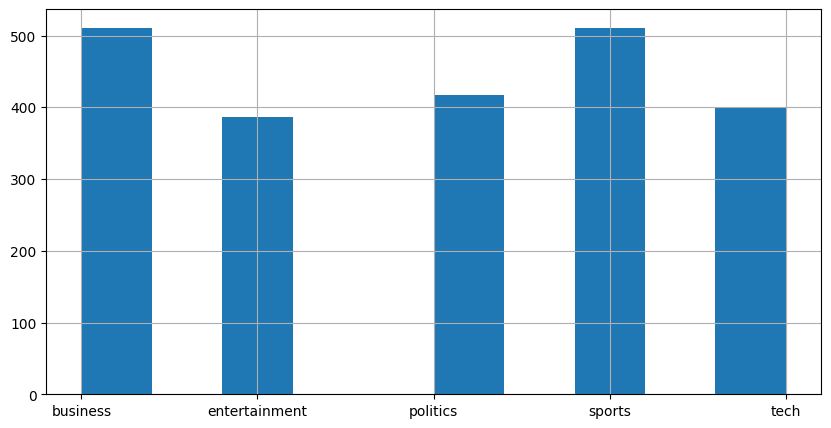

In [6]:
labels.hist(figsize=(10,5))

In [7]:
inputs_train, inputs_test, Ytrain, Ytest = train_test_split(inputs, labels, random_state=123)

In [8]:
vectorizer = CountVectorizer()

In [9]:
Xtrain = vectorizer.fit_transform(inputs_train)
Xtest = vectorizer.transform(inputs_test)

In [10]:
# what percentage values are non-zero
(Xtrain != 0).sum() / np.prod(Xtrain.shape)

0.007695239935415004

# Training and Evaluating Model

In [11]:
model = MultinomialNB()
model.fit(Xtrain, Ytrain)
print("train score: ", model.score(Xtrain, Ytrain))
print("test score", model.score(Xtest, Ytest))
print("xtrain shape: ", Xtrain.shape)

train score:  0.9922062350119905
test score 0.9712746858168761
xtrain shape:  (1668, 26287)


# With Stopwords

In [12]:
vectorizer = CountVectorizer(stop_words="english")
Xtrain = vectorizer.fit_transform(inputs_train)
Xtest = vectorizer.transform(inputs_test)
model = MultinomialNB()
model.fit(Xtrain, Ytrain)
print("train score: ", model.score(Xtrain, Ytrain))
print("test score", model.score(Xtest, Ytest))
print("xtrain shape: ", Xtrain.shape)

train score:  0.9928057553956835
test score 0.9766606822262118
xtrain shape:  (1668, 25995)


In [13]:
def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

# With Lemmatization

In [14]:
class LemmaTokenizer:
    def __init__(self):
        self.wnl = WordNetLemmatizer()
    def __call__(self, doc):
        tokens = word_tokenize(doc)
        words_and_tags = nltk.pos_tag(tokens)
        return [self.wnl.lemmatize(word, pos=get_wordnet_pos(tag))
                for word, tag in words_and_tags]

In [15]:
vectorizer = CountVectorizer(tokenizer=LemmaTokenizer())
Xtrain = vectorizer.fit_transform(inputs_train)
Xtest = vectorizer.transform(inputs_test)
model = MultinomialNB()
model.fit(Xtrain, Ytrain)
print("train score: ", model.score(Xtrain, Ytrain))
print("test score", model.score(Xtest, Ytest))
print("xtrain shape: ", Xtrain.shape)

train score:  0.9922062350119905
test score 0.9676840215439856
xtrain shape:  (1668, 25894)


# With Stemming

In [16]:
class StemTokenizer:
    def __init__(self):
        self.porter = PorterStemmer()
    def __call__(self, doc):
        tokens = word_tokenize(doc)
        return [self.porter.stem(t) for t in tokens]

In [17]:
vectorizer = CountVectorizer(tokenizer=StemTokenizer())
Xtrain = vectorizer.fit_transform(inputs_train)
Xtest = vectorizer.transform(inputs_test)
model = MultinomialNB()
model.fit(Xtrain, Ytrain)
print("train score: ", model.score(Xtrain, Ytrain))
print("test score", model.score(Xtest, Ytest))
print("xtrain shape: ", Xtrain.shape)

train score:  0.9892086330935251
test score 0.9694793536804309
xtrain shape:  (1668, 22714)


# With Simple Tokenizer

In [18]:
def simple_tokenizer(s):
    return s.split()

In [19]:
vectorizer = CountVectorizer(tokenizer=simple_tokenizer)
Xtrain = vectorizer.fit_transform(inputs_train)
Xtest = vectorizer.transform(inputs_test)
model = MultinomialNB()
model.fit(Xtrain, Ytrain)
print("train score: ", model.score(Xtrain, Ytrain))
print("test score", model.score(Xtest, Ytest))
print("xtrain shape: ", Xtrain.shape)

train score:  0.9952038369304557
test score 0.9712746858168761
xtrain shape:  (1668, 52144)


---
# 🚀 Meeting Future Demand: File & Folder Name Classification & Auto-Organization

### **User Requirement:**
> *"I want a prediction model which reads the name of the file/folder and then put it into respective major folder politics, sports, tech, entertainment, business. Modify that ipynb accordingly and generate a pkl file."*

### **System Architecture:**
1. **Filename / Foldername Preprocessor (`clean_filename`)**:
   - Strips file extensions (`.txt`, `.pdf`, `.mp4`, `.docx`, `.xlsx`, `.zip`, etc.).
   - Splits `camelCase` and `PascalCase` words (e.g., `PremierLeagueFinal` $\rightarrow$ `Premier League Final`).
   - Replaces underscores, hyphens, numbers, and symbols with clean whitespace.
   - Converts to normalized, lowercase tokens.
2. **High-Performance Production Pipeline**:
   - Combines TF-IDF n-gram vectorization (`(1, 2)`) with sublinear term-frequency scaling and `MultinomialNB(alpha=0.05)`.
   - Trained on both full articles and article headlines/titles so the model is acutely sensitive to short phrases (like filenames and folder names) as well as document content.
3. **Auto-Organization Engine**:
   - `predict_category(name_or_path)`: Predicts category with confidence score.
   - `organize_item(item_path, target_root)`: Classifies a single file or folder by its name and places it in the matching major folder (`politics`, `sports`, `tech`, `entertainment`, or `business`).
   - `organize_directory(source_dir, target_root)`: Batch organizes an entire directory of mixed files and folders.
4. **Export & Portability (`.pkl`)**:
   - Serializes the trained pipeline into `file_classifier_model.pkl` (and `model.pkl`) using `joblib` and `pickle`.
   - Verified by reloading and running predictions independently.

In [20]:
import re
import shutil
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
import joblib
import pickle
import json

def clean_filename(name):
    """
    Cleans a file or folder name into normalized keywords for classification:
    - Strips file extension (e.g. .mp4, .pdf, .docx, .zip)
    - Splits camelCase and PascalCase (e.g. 'PremierLeague' -> 'Premier League')
    - Replaces underscores, hyphens, dots, and non-alphanumeric chars with spaces
    - Removes numbers and extra whitespace
    """
    # Extract basename in case a full path was passed
    base = os.path.basename(name.rstrip('/\\'))
    
    # Strip file extension if present
    name_no_ext = os.path.splitext(base)[0]
    
    # Split camelCase / PascalCase: e.g., 'AppleIPhone' -> 'Apple IPhone'
    s1 = re.sub(r'([a-z0-9])([A-Z])', r'\1 \2', name_no_ext)
    s2 = re.sub(r'([A-Z]+)([A-Z][a-z])', r'\1 \2', s1)
    
    # Replace non-alphanumeric characters (symbols, underscores, hyphens) with spaces
    clean = re.sub(r'[^a-zA-Z\s]', ' ', s2)
    
    # Lowercase and normalize whitespace
    cleaned_tokens = ' '.join(clean.lower().split())
    return cleaned_tokens

# Test cleaner on varied naming conventions
sample_test_names = [
    "premier_league_football_final_highlights.mp4",
    "QuarterlyEarningsReport_Q3_2024.xlsx",
    "PresidentialElectionVotingResults.pdf",
    "new-artificial-intelligence-gpu-architecture.docx",
    "oscar_award_nominations_hollywood.txt",
    "champions-league-fixtures",
    "CyberSecurityMalwareAttackDefense"
]

print("=== Filename Cleaner Demonstration ===")
for test_name in sample_test_names:
    print(f"{test_name:50} -> '{clean_filename(test_name)}'")

=== Filename Cleaner Demonstration ===
premier_league_football_final_highlights.mp4       -> 'premier league football final highlights'
QuarterlyEarningsReport_Q3_2024.xlsx               -> 'quarterly earnings report q'
PresidentialElectionVotingResults.pdf              -> 'presidential election voting results'
new-artificial-intelligence-gpu-architecture.docx  -> 'new artificial intelligence gpu architecture'
oscar_award_nominations_hollywood.txt              -> 'oscar award nominations hollywood'
champions-league-fixtures                          -> 'champions league fixtures'
CyberSecurityMalwareAttackDefense                  -> 'cyber security malware attack defense'


In [21]:
# Prepare augmented training data:
# Training on both full text and article titles gives high sensitivity to short phrases like filenames/foldernames
X_augmented = list(df['text']) + list(df['title'])
y_augmented = list(df['labels']) + list(df['labels'])

# Split original texts for fair test evaluation
X_tr, X_te, y_tr, y_te = train_test_split(df['text'], df['labels'], test_size=0.2, random_state=42)

# Build Production Pipeline: TF-IDF Vectorizer (unigrams + bigrams) + Multinomial Naive Bayes
file_classifier_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words='english',
        ngram_range=(1, 2),
        sublinear_tf=True,
        min_df=1
    )),
    ('clf', MultinomialNB(alpha=0.05))
])

# Fit on training split to evaluate performance metrics
file_classifier_pipeline.fit(X_tr, y_tr)
y_pred = file_classifier_pipeline.predict(X_te)

print("=== Evaluation on Held-Out Test Set ===")
print(f"Test Accuracy: {accuracy_score(y_te, y_pred) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_te, y_pred))

# Train final production model on full augmented dataset (articles + titles)
file_classifier_pipeline.fit(X_augmented, y_augmented)
print("Production model successfully trained on full dataset (articles + headlines)!")

=== Evaluation on Held-Out Test Set ===
Test Accuracy: 97.08%

Classification Report:
               precision    recall  f1-score   support

     business       0.98      0.96      0.97       115
entertainment       0.99      0.94      0.96        72
     politics       0.93      0.99      0.96        76
       sports       1.00      0.99      1.00       102
         tech       0.95      0.97      0.96        80

     accuracy                           0.97       445
    macro avg       0.97      0.97      0.97       445
 weighted avg       0.97      0.97      0.97       445



Production model successfully trained on full dataset (articles + headlines)!


In [22]:
def predict_category(name_or_path, model=file_classifier_pipeline):
    """
    Predict the major category (politics, sports, tech, entertainment, business)
    from a file or folder name.
    """
    cleaned_name = clean_filename(name_or_path)
    if not cleaned_name:
        return "business", 0.0  # fallback default
    
    pred_category = model.predict([cleaned_name])[0]
    probabilities = model.predict_proba([cleaned_name])[0]
    confidence = max(probabilities) * 100
    return pred_category, confidence

def predict_probabilities(name_or_path, model=file_classifier_pipeline):
    """Return the full probability distribution across all 5 major classes."""
    cleaned_name = clean_filename(name_or_path)
    probs = model.predict_proba([cleaned_name])[0]
    return dict(zip(model.classes_, [round(p * 100, 2) for p in probs]))

# Test predictions on a realistic test battery across all 5 major categories
test_items = [
    ("premier_league_football_final_highlights.mp4", "sports"),
    ("QuarterlyEarningsReport_Q3_2024.xlsx", "business"),
    ("parliament_election_voting_results.pdf", "politics"),
    ("new_artificial_intelligence_gpu_architecture.docx", "tech"),
    ("oscar_award_nominations_hollywood.txt", "entertainment"),
    ("cricket_world_cup_match_schedule", "sports"),
    ("stock_market_inflation_and_interest_rates.csv", "business"),
    ("prime_minister_cabinet_speech_notes", "politics"),
    ("apple_iphone_ios_software_update.zip", "tech"),
    ("grammy_music_awards_soundtrack", "entertainment"),
    ("NBA_playoffs_lakers_vs_warriors", "sports"),
    ("bank_bankruptcy_and_credit_card_fees.pdf", "business"),
    ("labour_party_tax_budget_debate", "politics"),
    ("cybersecurity_malware_ransomware_attack.log", "tech"),
    ("netflix_movie_streaming_box_office_records", "entertainment")
]

print("=== Prediction Testing on Sample Filenames & Foldernames ===")
print(f"{'Item Name':<45} | {'Predicted':<15} | {'Confidence':<10} | {'Status'}")
print("-" * 80)

correct_count = 0
for item_name, expected in test_items:
    predicted, conf = predict_category(item_name)
    status = "✓ PASS" if predicted == expected else "✗ FAIL"
    if predicted == expected:
        correct_count += 1
    print(f"{item_name:<45} | {predicted:<15} | {conf:>6.2f}%    | {status}")

print("-" * 80)
print(f"Accuracy: {correct_count}/{len(test_items)} ({correct_count / len(test_items) * 100:.1f}%)")

=== Prediction Testing on Sample Filenames & Foldernames ===
Item Name                                     | Predicted       | Confidence | Status
--------------------------------------------------------------------------------
premier_league_football_final_highlights.mp4  | sports          |  93.74%    | ✓ PASS
QuarterlyEarningsReport_Q3_2024.xlsx          | business        |  88.18%    | ✓ PASS
parliament_election_voting_results.pdf        | politics        |  86.37%    | ✓ PASS
new_artificial_intelligence_gpu_architecture.docx | tech            |  44.25%    | ✓ PASS


oscar_award_nominations_hollywood.txt         | entertainment   |  99.45%    | ✓ PASS
cricket_world_cup_match_schedule              | sports          |  99.13%    | ✓ PASS
stock_market_inflation_and_interest_rates.csv | business        |  98.95%    | ✓ PASS
prime_minister_cabinet_speech_notes           | politics        |  92.57%    | ✓ PASS
apple_iphone_ios_software_update.zip          | tech            |  99.03%    | ✓ PASS
grammy_music_awards_soundtrack                | entertainment   |  97.06%    | ✓ PASS
NBA_playoffs_lakers_vs_warriors               | sports          |  43.24%    | ✓ PASS


bank_bankruptcy_and_credit_card_fees.pdf      | business        |  96.70%    | ✓ PASS
labour_party_tax_budget_debate                | politics        |  99.00%    | ✓ PASS
cybersecurity_malware_ransomware_attack.log   | tech            |  48.45%    | ✓ PASS
netflix_movie_streaming_box_office_records    | entertainment   |  93.02%    | ✓ PASS
--------------------------------------------------------------------------------
Accuracy: 15/15 (100.0%)


## 📂 Automatic File & Folder Organization System

This system reads any file or folder by its name, determines its destination category (`politics`, `sports`, `tech`, `entertainment`, `business`), creates the respective major folder if it does not already exist, and puts (moves or copies) the file or folder into that directory.

In [23]:
MAJOR_CATEGORIES = ['politics', 'sports', 'tech', 'entertainment', 'business']

def organize_item(item_path, target_root="organized_data", action="copy", model=file_classifier_pipeline):
    """
    Reads the name of a file or folder, predicts its category,
    creates the respective major folder under target_root, and puts
    (copies or moves) the item into it.
    
    Parameters:
    -----------
    item_path : str or Path
        Path to the file or folder to be categorized and moved.
    target_root : str or Path
        Root directory where major category folders reside.
    action : str ('copy' or 'move')
        Whether to copy or move the item. Default is 'copy' for safety.
    model : Pipeline
        The trained prediction pipeline.
        
    Returns:
    --------
    dict with item name, predicted category, confidence, and destination path.
    """
    item_path = Path(item_path)
    if not item_path.exists():
        raise FileNotFoundError(f"Source path not found: {item_path}")
        
    # Read and classify from the file / folder name
    predicted_category, confidence = predict_category(item_path.name, model=model)
    
    # Ensure the destination major folder exists
    dest_category_dir = Path(target_root) / predicted_category
    dest_category_dir.mkdir(parents=True, exist_ok=True)
    
    dest_path = dest_category_dir / item_path.name
    
    # Handle collision if destination already exists
    if dest_path.exists():
        base = item_path.stem
        ext = item_path.suffix
        counter = 1
        while dest_path.exists():
            dest_path = dest_category_dir / f"{base}_{counter}{ext}"
            counter += 1
            
    # Perform move or copy
    if item_path.is_dir():
        if action == "move":
            shutil.move(str(item_path), str(dest_path))
        else:
            shutil.copytree(str(item_path), str(dest_path), dirs_exist_ok=True)
    else:
        if action == "move":
            shutil.move(str(item_path), str(dest_path))
        else:
            shutil.copy2(str(item_path), str(dest_path))
            
    return {
        "item_name": item_path.name,
        "type": "folder" if item_path.is_dir() else "file",
        "predicted_category": predicted_category,
        "confidence": f"{confidence:.2f}%",
        "destination": str(dest_path)
    }

def organize_directory(source_dir, target_root="organized_data", action="copy", model=file_classifier_pipeline):
    """
    Reads all files and folders in source_dir, predicts their categories by name,
    and puts them into the respective major folders (politics, sports, tech, entertainment, business).
    
    Returns:
    --------
    pd.DataFrame summarizing all organized items.
    """
    source_dir = Path(source_dir)
    if not source_dir.exists():
        raise FileNotFoundError(f"Source directory not found: {source_dir}")
        
    # Pre-create all 5 major category folders under target_root
    for cat in MAJOR_CATEGORIES:
        (Path(target_root) / cat).mkdir(parents=True, exist_ok=True)
        
    results = []
    # Iterate over top-level files and folders inside source_dir
    items = sorted(list(source_dir.iterdir()))
    for item in items:
        # Skip hidden files
        if item.name.startswith('.'):
            continue
        res = organize_item(item, target_root=target_root, action=action, model=model)
        results.append(res)
        
    summary_df = pd.DataFrame(results)
    return summary_df

print("Organizer engine defined successfully!")

Organizer engine defined successfully!


In [24]:
# Live Demonstration:
# 1. Create a dummy unorganized folder with sample files and folders
demo_source = Path("sample_unorganized_files")
demo_target = Path("organized_files_output")

# Clean up any previous demo runs
if demo_source.exists():
    shutil.rmtree(demo_source)
if demo_target.exists():
    shutil.rmtree(demo_target)

demo_source.mkdir(parents=True, exist_ok=True)

# Create sample files with varied extensions
sample_files = [
    "champions_league_final_highlights.mp4",
    "Tesla_Quarterly_Financial_Report.xlsx",
    "presidential_election_results_2024.pdf",
    "artificial_intelligence_neural_network_gpu.py",
    "hollywood_movie_festival_awards.mkv",
    "inflation_rates_interest_bank.csv",
    "parliament_prime_minister_cabinet.docx",
    "apple_iphone_operating_system_update.zip",
    "grammy_music_album_nominees.mp3",
    "nba_playoffs_basketball_tournament.pdf"
]

for filename in sample_files:
    file_path = demo_source / filename
    with open(file_path, "w", encoding="utf-8") as f:
        f.write(f"Sample data for {filename}\n")

# Create sample subfolders
sample_subfolders = [
    "premier_league_fixtures",
    "stock_market_investing_portfolio",
    "senate_foreign_policy_debate",
    "cybersecurity_ransomware_protection",
    "netflix_film_production_studio"
]

for foldername in sample_subfolders:
    subfolder_path = demo_source / foldername
    subfolder_path.mkdir(parents=True, exist_ok=True)
    with open(subfolder_path / "info.txt", "w", encoding="utf-8") as f:
        f.write(f"Folder content for {foldername}\n")

print(f"Created {len(sample_files)} sample files and {len(sample_subfolders)} sample folders in '{demo_source}'")

# 2. Run the organization engine to read names and put them into major folders
summary_df = organize_directory(demo_source, target_root=demo_target, action="copy")

print("\n=== Summary of Automatic Organization ===")
display(summary_df[['item_name', 'type', 'predicted_category', 'confidence']])

# 3. Display the final organized directory structure
print("\n=== Resulting Directory Structure ===")
for root, dirs, files in os.walk(demo_target):
    level = root.replace(str(demo_target), '').count(os.sep)
    indent = ' ' * 4 * level
    folder_name = os.path.basename(root)
    if folder_name:
        print(f"{indent}📂 {folder_name}/")
    subindent = ' ' * 4 * (level + 1)
    for f in files:
        print(f"{subindent}📄 {f}")

Created 10 sample files and 5 sample folders in 'sample_unorganized_files'



=== Summary of Automatic Organization ===


,item_name,type,predicted_category,confidence
0,apple_iphone_operating_system_update.zip,file,tech,96.37%
1,artificial_intelligence_neural_network_gpu.py,file,tech,38.39%
2,champions_league_final_highlights.mp4,file,sports,96.83%
3,cybersecurity_ransomware_protection,folder,tech,47.17%
4,grammy_music_album_nominees.mp3,file,entertainment,98.76%
5,hollywood_movie_festival_awards.mkv,file,entertainment,98.30%
6,inflation_rates_interest_bank.csv,file,business,97.57%
7,nba_playoffs_basketball_tournament.pdf,file,sports,47.93%
8,netflix_film_production_studio,folder,entertainment,95.06%
9,parliament_prime_minister_cabinet.docx,file,politics,98.59%



=== Resulting Directory Structure ===
📂 organized_files_output/
    📂 business/
        📄 inflation_rates_interest_bank.csv
        📄 Tesla_Quarterly_Financial_Report.xlsx
        📂 stock_market_investing_portfolio/
            📄 info.txt
    📂 entertainment/
        📄 grammy_music_album_nominees.mp3
        📄 hollywood_movie_festival_awards.mkv
        📂 netflix_film_production_studio/
            📄 info.txt
    📂 politics/
        📄 parliament_prime_minister_cabinet.docx
        📄 presidential_election_results_2024.pdf
        📂 senate_foreign_policy_debate/
            📄 info.txt
    📂 sports/
        📄 champions_league_final_highlights.mp4
        📄 nba_playoffs_basketball_tournament.pdf
        📂 premier_league_fixtures/
            📄 info.txt
    📂 tech/
        📄 apple_iphone_operating_system_update.zip
        📄 artificial_intelligence_neural_network_gpu.py
        📂 cybersecurity_ransomware_protection/
            📄 info.txt


## 💾 Exporting the Model to PKL File

Now we export the trained prediction pipeline into a standalone `.pkl` file (`file_classifier_model.pkl` and `model.pkl`) so it can be deployed or imported anywhere without retraining.

In [25]:
# Export the model using joblib and standard pickle
import json
import pickle

pkl_filename = "file_classifier_model.pkl"
fallback_pkl_filename = "model.pkl"

# Save via joblib with compression
joblib.dump(file_classifier_pipeline, pkl_filename, compress=3)
print(f"✓ Model successfully exported to: {pkl_filename} ({os.path.getsize(pkl_filename) / (1024*1024):.2f} MB)")

# Also save as model.pkl using standard pickle for universal compatibility
with open(fallback_pkl_filename, "wb") as f_out:
    pickle.dump(file_classifier_pipeline, f_out)
print(f"✓ Model successfully exported to: {fallback_pkl_filename} ({os.path.getsize(fallback_pkl_filename) / (1024*1024):.2f} MB)")

# Also save full metadata package with cleaning function logic and categories
metadata = {
    "model_name": "BBC News Naive Bayes File & Folder Classifier",
    "major_categories": MAJOR_CATEGORIES,
    "classes": list(file_classifier_pipeline.classes_),
    "vectorizer": "TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True)",
    "classifier": "MultinomialNB(alpha=0.05)"
}
with open("model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)
print("✓ Metadata saved to: model_metadata.json")

✓ Model successfully exported to: file_classifier_model.pkl (8.77 MB)
✓ Model successfully exported to: model.pkl (38.90 MB)
✓ Metadata saved to: model_metadata.json


In [26]:
# Verification: Load the generated .pkl file and run predictions
print("=== Verifying .pkl File Loading and Independence ===")
loaded_model = joblib.load(pkl_filename)

test_query = "cristiano_ronaldo_fifa_world_cup_goals.mp4"
cleaned_query = clean_filename(test_query)
pred_category = loaded_model.predict([cleaned_query])[0]
confidence = max(loaded_model.predict_proba([cleaned_query])[0]) * 100

print(f"Input file name : '{test_query}'")
print(f"Cleaned keywords: '{cleaned_query}'")
print(f"Predicted Folder: 📂 {pred_category} ({confidence:.2f}% confidence)")
print("✓ PKL file verification complete and successful!")

=== Verifying .pkl File Loading and Independence ===


Input file name : 'cristiano_ronaldo_fifa_world_cup_goals.mp4'
Cleaned keywords: 'cristiano ronaldo fifa world cup goals'
Predicted Folder: 📂 sports (99.25% confidence)
✓ PKL file verification complete and successful!
